In [1]:
import ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

main_dir = '/home/gap2/Downloads/PPRL-Dev-main/results/matching/D2/'

In [2]:
df_cosine = pd.read_csv(main_dir + 'cosine.csv')
df_cosine['similarity'] = 'cosine'
df_dice = pd.read_csv(main_dir + 'dice.csv')
df_dice['similarity'] = 'dice'
df_jaccard = pd.read_csv(main_dir + 'jaccard.csv')
df_jaccard['similarity'] = 'jaccard'
df_scm = pd.read_csv(main_dir + 'scm.csv')
df_scm['similarity'] = 'scm'

In [3]:
result = pd.DataFrame()
dfs = [df_cosine, df_dice, df_jaccard, df_scm]
for df in dfs:
    result = pd.concat([result, df], ignore_index=True, sort=False)

result['config_dict'] = result['config'].apply(ast.literal_eval)
config_cols = pd.json_normalize(result['config_dict'])
result = result.join(config_cols)
result = result.drop(columns=['config', 'config_dict'])
result

,name,total_matches,similarity_threshold,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,similarity,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
0,Matching with cosine,55983,0.20,1.89,99.44,3.71,1058,54925,1070,6,cosine,[name],1024,0,1,salted_qgrams,,4
1,Matching with cosine,33452,0.25,3.16,99.34,6.12,1057,32395,1069,7,cosine,[name],1024,0,1,salted_qgrams,,4
2,Matching with cosine,102357,0.15,1.04,99.72,2.05,1061,101296,1073,3,cosine,[name],1024,0,1,salted_qgrams,,4
3,Matching with cosine,20462,0.30,5.11,98.21,9.71,1045,19417,1057,19,cosine,[name],1024,0,1,salted_qgrams,,4
4,Matching with cosine,13021,0.35,7.91,96.80,14.63,1030,11991,1042,34,cosine,[name],1024,0,1,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2427,Matching with scm,1144864,0.15,0.09,100.00,0.19,1064,1143800,1076,0,scm,[name],1024,0,32,salted_qgrams,,4
2428,Matching with scm,1141768,0.40,0.09,100.00,0.19,1064,1140704,1076,0,scm,[name],1024,0,32,salted_qgrams,,4
2429,Matching with scm,1122372,0.45,0.09,100.00,0.19,1064,1121308,1076,0,scm,[name],1024,0,32,salted_qgrams,,4
2430,Matching with scm,1144864,0.25,0.09,100.00,0.19,1064,1143800,1076,0,scm,[name],1024,0,32,salted_qgrams,,4


In [4]:
result['attributes'].value_counts()

attributes
[name]    2432
Name: count, dtype: int64

In [5]:
result['offset'].value_counts()

offset
0    2432
Name: count, dtype: int64

In [6]:
result['hashing_type'].value_counts()

hashing_type
salted_qgrams    2432
Name: count, dtype: int64

In [7]:
result['qgrams'].value_counts()

qgrams
4    2432
Name: count, dtype: int64

In [8]:
result['size'].value_counts()

size
1024    2432
Name: count, dtype: int64

In [9]:
result['num_hashes'].value_counts()

num_hashes
1     76
2     76
3     76
4     76
5     76
6     76
7     76
8     76
9     76
10    76
11    76
12    76
13    76
14    76
15    76
16    76
17    76
18    76
19    76
20    76
21    76
22    76
23    76
24    76
25    76
26    76
27    76
28    76
29    76
30    76
31    76
32    76
Name: count, dtype: int64

In [10]:
max_f1 = result.loc[result.groupby(['num_hashes','similarity'])['F1 %'].idxmax()]
max_f1

,name,total_matches,similarity_threshold,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,similarity,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
11,Matching with cosine,1515,0.65,40.99,58.36,48.16,621,894,633,443,cosine,[name],1024,0,1,salted_qgrams,,4
620,Matching with dice,1423,0.65,41.25,55.17,47.21,587,836,599,477,dice,[name],1024,0,1,salted_qgrams,,4
1226,Matching with jaccard,1326,0.50,42.16,52.54,46.78,559,767,571,505,jaccard,[name],1024,0,1,salted_qgrams,,4
1824,Matching with scm,201537,0.95,0.51,95.68,1.00,1018,200519,1030,46,scm,[name],1024,0,1,salted_qgrams,,4
29,Matching with cosine,1570,0.65,40.38,59.59,48.14,634,936,646,430,cosine,[name],1024,0,2,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2398,Matching with scm,466,0.85,63.30,27.73,38.56,295,171,307,769,scm,[name],1024,0,31,salted_qgrams,,4
591,Matching with cosine,707,0.90,35.93,23.87,28.68,254,453,266,810,cosine,[name],1024,0,32,salted_qgrams,,4
1197,Matching with dice,655,0.90,37.71,23.21,28.74,247,408,259,817,dice,[name],1024,0,32,salted_qgrams,,4
1808,Matching with jaccard,1135,0.80,25.11,26.79,25.92,285,850,297,779,jaccard,[name],1024,0,32,salted_qgrams,,4


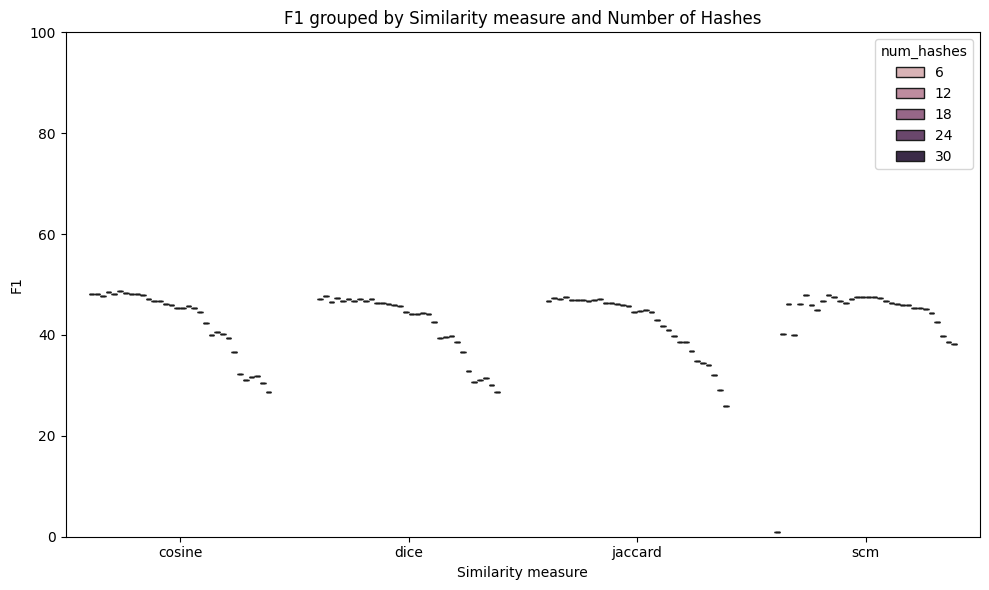

In [11]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=max_f1,
    x="similarity",
    y="F1 %",
    hue="num_hashes"
)

plt.title("F1 grouped by Similarity measure and Number of Hashes")
plt.xlabel("Similarity measure")
plt.ylabel("F1")
plt.ylim(0, 100) 
plt.legend(title="num_hashes")
plt.tight_layout()
plt.show()

In [12]:
metrics_df = max_f1.melt(
    id_vars=["similarity", "num_hashes"],
    value_vars=["Precision %", "Recall %", "F1 %"],
    var_name="Metric",
    value_name="Score"
)
metrics_df

,similarity,num_hashes,Metric,Score
0,cosine,1,Precision %,40.99
1,dice,1,Precision %,41.25
2,jaccard,1,Precision %,42.16
3,scm,1,Precision %,0.51
4,cosine,2,Precision %,40.38
...,...,...,...,...
379,scm,31,F1 %,38.56
380,cosine,32,F1 %,28.68
381,dice,32,F1 %,28.74
382,jaccard,32,F1 %,25.92


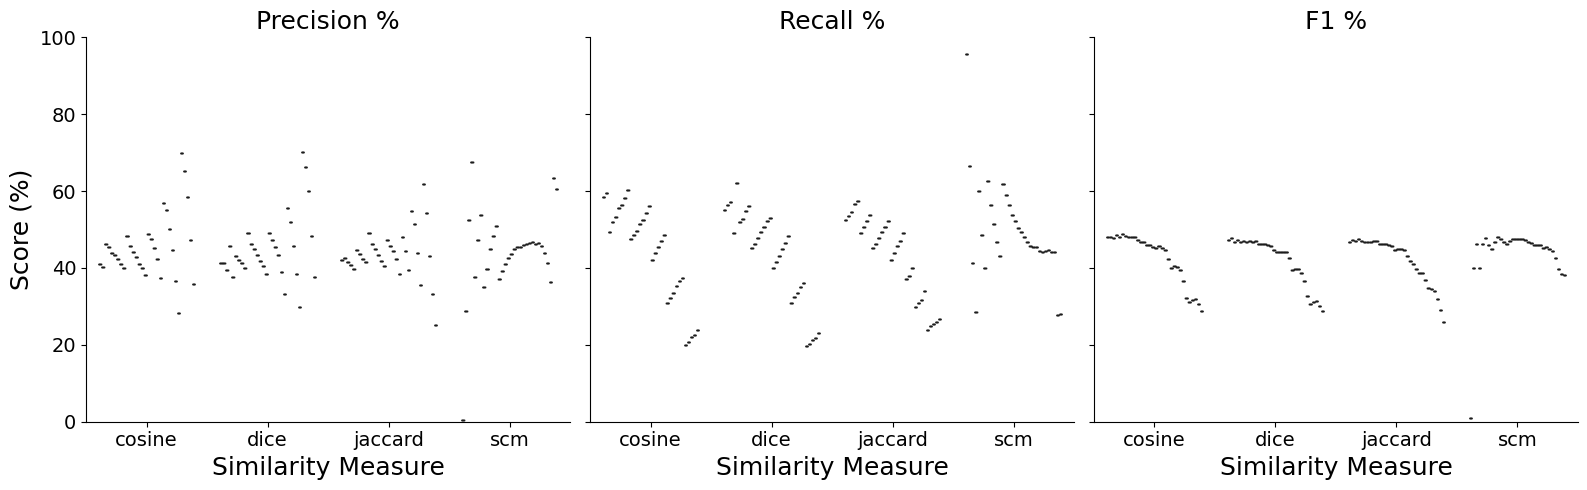

In [13]:
g = sns.catplot(
    data=metrics_df,
    x="similarity",
    y="Score",
    hue="num_hashes",
    col="Metric",
    kind="box",
    height=5,
    aspect=1,
    fliersize=14  # increase dot size
)
g._legend.remove()
g.set(ylim=(0, 100))
g.set_axis_labels("Similarity Measure", "Score (%)", fontsize=18)
g.set_titles("{col_name}", size=18)
for ax in g.axes.flat:
    ax.tick_params(axis='both', labelsize=14)
plt.tight_layout()
plt.show()

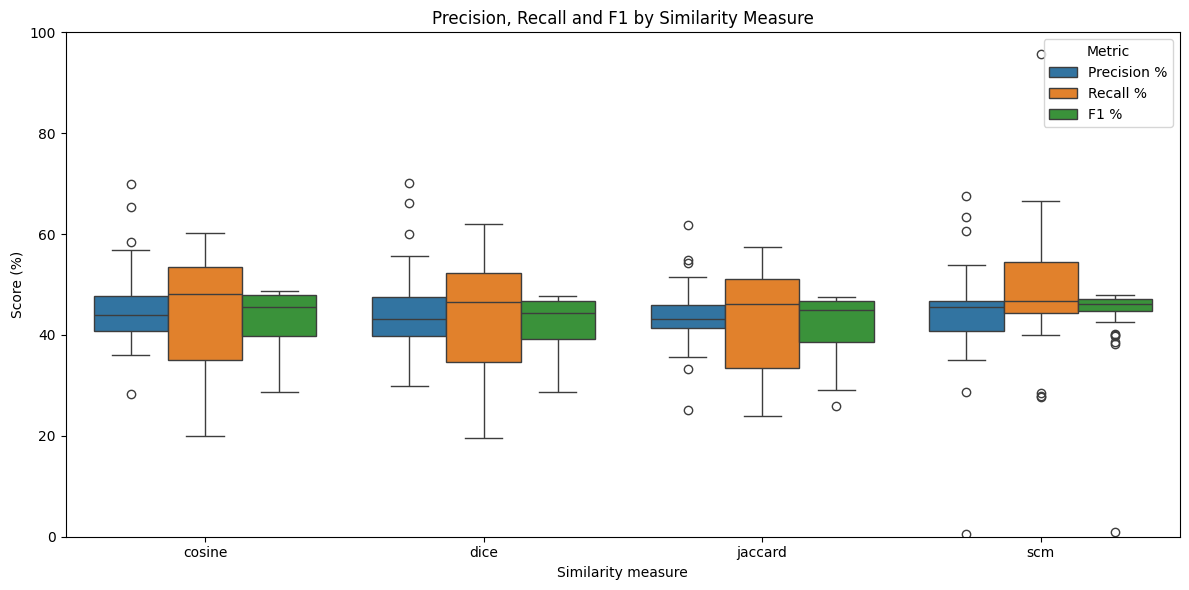

In [14]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=metrics_df,
    x="similarity",
    y="Score",
    hue="Metric"
)

plt.title("Precision, Recall and F1 by Similarity Measure")
plt.xlabel("Similarity measure")
plt.ylabel("Score (%)")
plt.ylim(0, 100) 
plt.legend(title="Metric")
plt.tight_layout()
plt.show()